# Lab 03: Data Cleaning

*Grundlagen der Data Science*, week 03. **Plan for about 60 minutes.**

A student flat-share portal dumped its listings into `data/rents_export.csv`: three years of
exports, three different export formats, and nobody cleaned up in between. To compare the listings
with the city's official rent table (`data/district_rents.csv`) we first have to repair the export.

| Task | What you practise |
| --- | --- |
| 1 | Profile the export: shape, types, missing values |
| 2 | Repair the amounts (German decimal comma, units, currency) |
| 3 | Find disguised missing values and remove them |
| 4 | Restrict the scope and roll the data up to district granularity |
| 5 | Standardize the district names and join with the official table |
| 6 | Detect and remove the duplicate listings |

Fill in the cells marked `# YOUR CODE HERE`. Each one is followed by a test cell with `assert`s:
if it prints nothing, your answer is fine. Answers to the questions go into the cells marked
`YOUR ANSWER HERE`.

The data is synthetic: generated for this lab, with the quality problems planted on purpose. The
`data/readme.txt` says what each column means.


In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rents = pd.read_csv("data/rents_export.csv")
official = pd.read_csv("data/district_rents.csv")

rents.head()


,listing_id,address,district,zip_code,city,living_area,cold_rent_eur,lease_date
0,1001,101 Osterstraße,Hannover-Mitte,30159,Hannover,NaN,"504,17",2022-02-04
1,1002,121 Osterstraße,mitte,30159,Hannover,"111,6 m²",1536.54,7.3.2023
2,1003,31 Georgstraße,mitte,30159,Hannover,999,655 €,10.04.2024
3,1004,51 Georgstraße,Mitte,30159,Hannover,"34,5","495,74 €",2021-05-13
4,1005,71 Georgstraße,Hannover-Mitte,30159,Hannover,82.7,999,16.6.2022


## Task 1: Profile the export

Before touching anything: how big is the table, which columns are text although they should be
numbers, where are values missing? `rents.info()` and `rents.isna()` answer the first and last
question. (The `lease_date` column is text, too: three different date formats are mixed in there.
Note it; Task 6 comes back to it.)

Count the **missing cells** of the whole table (all columns together).


In [2]:
rents.info()
print()
print(rents.isna().sum())


<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   listing_id     58 non-null     int64
 1   address        58 non-null     str  
 2   district       58 non-null     str  
 3   zip_code       58 non-null     int64
 4   city           58 non-null     str  
 5   living_area    50 non-null     str  
 6   cold_rent_eur  58 non-null     str  
 7   lease_date     58 non-null     str  
dtypes: int64(2), str(6)
memory usage: 3.8 KB

listing_id       0
address          0
district         0
zip_code         0
city             0
living_area      8
cold_rent_eur    0
lease_date       0
dtype: int64


In [3]:
# YOUR CODE HERE

n_missing_cells = rents.isna().sum().sum()

In [4]:
assert n_missing_cells == 8, f"expected 8 missing cells, got {n_missing_cells}"


## Task 2: Repair the amounts

`living_area` and `cold_rent_eur` are text columns (dtype `str`): some rows hold numbers, most
hold text in a different notation: `"82,5 m²"`, `"1.250,50 €"`, `"447.56"`. The lecture calls
this *units not specified or consistent*.

Write a function `parse_amount` that turns one such value into a `float`:

- `NaN` stays `NaN`, a real number is returned as `float`
- strip the currency sign `€` and the unit `m²`
- **the trap:** in `"1.000,16 €"` a dot is a thousands separator, in `"447.56"` it is the decimal
  separator. Use the comma to decide: if the text contains a comma, the dots are thousands
  separators, otherwise the dot is the decimal separator.

Then apply it to both columns.


In [5]:
def parse_amount(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float)):
        return float(value)

    value = value.replace("€", "").replace("m²", "").strip()
    print("1: " + value)

    if "," in value:
        value = value.replace(".", "")
        value = value.replace(",", ".")

    

    print("2: " + value)
    return float(value)
    


rents["living_area"] = rents["living_area"].map(parse_amount)
rents["cold_rent_eur"] = rents["cold_rent_eur"].map(parse_amount)


1: 111,6
2: 111.6
1: 999
2: 999
1: 34,5
2: 34.5
1: 82.7
2: 82.7
1: 41.9
2: 41.9
1: 35,8
2: 35.8
1: 64.0
2: 64.0
1: 84.2
2: 84.2
1: 94.3
2: 94.3
1: 78,4
2: 78.4
1: 78.4
2: 78.4
1: 999
2: 999
1: 39,7
2: 39.7
1: 100,6
2: 100.6
1: 69.0
2: 69.0
1: 85.2
2: 85.2
1: 37,0
2: 37.0
1: 118.5
2: 118.5
1: 62.7
2: 62.7
1: 34,7
2: 34.7
1: 999
2: 999
1: 94.6
2: 94.6
1: 50,6
2: 50.6
1: 78,3
2: 78.3
1: 48.0
2: 48.0
1: 106.2
2: 106.2
1: 55,5
2: 55.5
1: 55.5
2: 55.5
1: 39.8
2: 39.8
1: 104.8
2: 104.8
1: 999
2: 999
1: 64,9
2: 64.9
1: 75.5
2: 75.5
1: 96.8
2: 96.8
1: 97,2
2: 97.2
1: 81.5
2: 81.5
1: 41,0
2: 41.0
1: 113,4
2: 113.4
1: 85.4
2: 85.4
1: 39.7
2: 39.7
1: 999
2: 999
1: 72,7
2: 72.7
1: 90.8
2: 90.8
1: 92.0
2: 92.0
1: 33,0
2: 33.0
1: 32.3
2: 32.3
1: 30.5
2: 30.5
1: 75.6
2: 75.6
1: 71,0
2: 71.0
1: 999
2: 999
1: 504,17
2: 504.17
1: 1536.54
2: 1536.54
1: 655
2: 655
1: 495,74
2: 495.74
1: 999
2: 999
1: 579.03
2: 579.03
1: -1
2: -1
1: 838.4
2: 838.4
1: 838
2: 838
1: 1156,56
2: 1156.56
1: 1209.27
2: 1209.27
1:

In [6]:
assert rents["living_area"].dtype == "float64", "living_area is still not numeric"
assert rents["cold_rent_eur"].dtype == "float64", "cold_rent_eur is still not numeric"
assert np.isclose(parse_amount("1.000,16 €"), 1000.16), "thousands dot not handled"
assert np.isclose(parse_amount("447.56"), 447.56), "decimal dot not handled"
assert np.isclose(rents["cold_rent_eur"].sum(skipna=True), 45717.36, atol=0.01)
assert np.isclose(rents["living_area"].sum(skipna=True), 9073.8, atol=0.01)


1: 1.000,16
2: 1000.16
1: 447.56
2: 447.56


## Task 3: Disguised missing values

The cell below lists the most frequent values of both columns. `999` is the most frequent rent
**and** the most frequent living area. One rent of 999 € would be plausible, but five of them,
among rents that otherwise almost never repeat, are not. And a flat of 999 m² does not exist. A
rent of `-1` is impossible. These are **disguised missing values**: the export writes a
placeholder instead of leaving the field empty.

Replace them with `NaN`: `999` in `living_area`, and `999` or `-1` in `cold_rent_eur`. Count how
many **values** you replaced (a row can have two of them).


In [7]:
print(rents["cold_rent_eur"].value_counts().head(4).to_string())
print()
print(rents["living_area"].value_counts().head(3).to_string())


cold_rent_eur
 999.00     5
-1.00       4
 1027.04    2
 547.20     2

living_area
999.0    6
78.4     2
39.7     2


In [8]:
# YOUR CODE HERE

n_disguised_values = 0

def parse_disguised_missing(value):
    global n_disguised_values
    
    if value == 999 or value == -1:
        n_disguised_values += 1
        return np.nan
        
    return value

rents["living_area"] = rents["living_area"].map(parse_disguised_missing)
rents["cold_rent_eur"] = rents["cold_rent_eur"].map(parse_disguised_missing)

n_disguised_values


15

In [9]:
assert n_disguised_values == 15, f"expected 15 disguised values, got {n_disguised_values}"
assert (rents["living_area"] == 999).sum() == 0, "a 999 area is still in the table"
assert not rents["cold_rent_eur"].isin([999, -1]).any(), "a 999 / -1 rent is still in the table"
assert np.isclose(rents["living_area"].mean(), 70.0, atol=0.01), "the mean area is still distorted"
assert rents["cold_rent_eur"].isna().sum() == 9


## Task 4: Scope and granularity

Three of the listings are in Laatzen and Garbsen, outside the city whose rent table we want to
compare with. Filter the table down to Hannover; the `city` column is written in different
capitalizations, so compare case-insensitively.

Then roll the listings up to **one row per district**: the official table has one row per district,
our export has one row per flat. `groupby` gets us there.

Keep the filtered table in `in_scope` and the district means in `rent_by_district`.


In [10]:
# YOUR CODE HERE


in_scope = rents[rents["city"].str.lower() == "hannover"]

rent_by_district = in_scope.groupby("district")["cold_rent_eur"].mean()


In [11]:
assert len(in_scope) == 55, f"expected 55 listings in Hannover, got {len(in_scope)}"
assert rent_by_district.size == 18, f"expected 18 district labels, got {rent_by_district.size}"
assert np.isclose(rent_by_district.max(), 1243.28, atol=0.01)


**Question:** Hannover has ten districts, but `rent_by_district` has 18 rows. What went wrong, and
what would this do to a plot of the average rent per district?

YOUR ANSWER HERE


## Task 5: Standardize the district names and join

Now the actual repair from the lecture: convert the different representations of a district into
one standard form, in **both** tables, and join them.

Write `normalize(label)`:

- strip whitespace, lowercase
- remove a leading `hannover-` / `hannover ` prefix
- transliterate `ä → ae`, `ö → oe`, `ü → ue`, `ß → ss`

The rest of the cell is given: it applies `normalize` to both tables (new column
`district_key`), averages the rent per district key and merges the result with the official
table. The merged table `joined` should have one row per district.


In [12]:
def normalize(label):
    # YOUR CODE HERE
    label = label.lower().strip()
    label = label.replace("hannover-", "").replace("hannover", "")
    label = label.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue").replace("ß", "ss")
    
    return label


in_scope["district_key"] = in_scope["district"].map(normalize)
official["district_key"] = official["district"].map(normalize)

rent_estimate = in_scope.groupby("district_key")["cold_rent_eur"].mean().rename("mean_cold_rent")
joined = rent_estimate.to_frame().merge(official, on="district_key", how="inner")
joined


,district_key,mean_cold_rent,district,avg_rent_per_m2,source_year
0,bothfeld,518.150000,Bothfeld,11.9,2024
1,doehren,933.650000,Döhren,11.1,2024
2,kirchrode,888.960000,Kirchrode,12.9,2024
3,linden,719.283750,Linden,11.4,2024
4,list,958.963750,List,13.1,2024
5,mitte,797.862500,Mitte,14.6,2024
6,nordstadt,826.452000,Nordstadt,12.2,2024
7,ricklingen,864.506667,Ricklingen,9.8,2024
8,suedstadt,935.545000,Südstadt,13.8,2024
9,vahrenwald,886.586667,Vahrenwald,10.7,2024


In [13]:
assert normalize("Hannover-Linden") == "linden"
assert normalize("SUEDSTADT") == "suedstadt"
assert normalize("List ") == "list"
assert len(joined) == 10, f"expected 10 districts after standardizing, got {len(joined)}"
assert joined["avg_rent_per_m2"].notna().all(), "the join lost the official numbers"
assert np.isclose(joined["mean_cold_rent"].sum(), 8329.96, atol=0.05)


## Task 6: Duplicate listings

Some flats were entered twice (by the landlord and again by the agency) with the address typed
slightly differently. Comparing every listing with every other one is quadratic, so the lecture's
answer is **blocking**: compare only inside a block of records that must belong together. Here we
block on the zip code (a flat cannot move), and inside a block only pairs with the same house
number are candidates.

Afterwards we remove the duplicates.

The cell below gives you the edit distance, the normalized addresses, the zip blocks and the
comparison counts.


In [14]:
def levenshtein(a, b):
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, 1):
        current = [i]
        for j, char_b in enumerate(b, 1):
            current.append(min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (char_a != char_b)))
        previous = current
    return previous[-1]


work = in_scope.assign(
    address_key=in_scope["address"].map(normalize),
    house_number=in_scope["address"].str.extract(r"^\s*(\d+)")[0],
)
zip_blocks = work.groupby("zip_code")["address_key"].apply(list)

n_comparisons_naive = len(work) * (len(work) - 1) // 2
n_comparisons_blocked = sum(len(block) * (len(block) - 1) // 2 for block in zip_blocks)
print(f"{n_comparisons_naive} comparisons naive, {n_comparisons_blocked} with zip blocking")


1485 comparisons naive, 141 with zip blocking


Collect all **duplicate pairs** into the list `duplicate_pairs`: two listings are duplicates if
they share zip code and house number and their normalized addresses are at most **2 edits** apart.
`n_duplicate_pairs` counts them.

In reality, the same address does not have to mean the same flat: a building has many flats,
and our addresses have no flat number. For this exercise we assume that one address is one flat,
so two listings with the same address are a duplicate.


In [20]:
duplicate_pairs = []

for zip_code, block in work.groupby("zip_code"):
    for i in range(len(block)):
        for j in range(i + 1, len(block)):

            if block.iloc[i]["house_number"] != block.iloc[j]["house_number"]:
                continue

            a = block.iloc[i]["address_key"]
            b = block.iloc[j]["address_key"]

            if levenshtein(a, b) <= 2:
                duplicate_pairs.append((a, b))

n_duplicate_pairs = len(duplicate_pairs)

In [21]:
assert n_comparisons_naive == 1485
assert n_comparisons_blocked == 141
assert n_duplicate_pairs == 5, f"expected 5 duplicate pairs, got {n_duplicate_pairs}"
assert ("88 hauptstraase", "88 hauptstrasse") in duplicate_pairs


### Removing the duplicates

Of each pair we keep the **newer** listing: it is the current offer. "Newer" needs the lease date,
and that column still mixes three formats (Task 1). The cell below shows the trap first:
`pd.to_datetime(..., format="mixed", dayfirst=True)` reads `7.3.2023` correctly as 7 March, but
it also turns the ISO date `2022-02-04` into 2 April. The safe way is to parse each format on its
own and combine the results.

Run the cell and look at the pairs in the table at the end.


In [22]:
one_call = pd.to_datetime(work["lease_date"], format="mixed", dayfirst=True)
print(work["lease_date"].iloc[0], "->", one_call.iloc[0].date(), " (wrong: day and month swapped)")

iso_dates = pd.to_datetime(work["lease_date"], format="%Y-%m-%d", errors="coerce")
german_dates = pd.to_datetime(work["lease_date"], format="%d.%m.%Y", errors="coerce")
work["lease_start"] = iso_dates.fillna(german_dates)
print(work["lease_date"].iloc[0], "->", work["lease_start"].iloc[0].date())

in_pair = work["address_key"].isin([address for pair in duplicate_pairs for address in pair])
newest = (work[in_pair].sort_values("lease_start")
          .drop_duplicates(["zip_code", "house_number"], keep="last"))
deduplicated = pd.concat([work[~in_pair], newest]).sort_index()
print(f"{len(work)} listings, {len(deduplicated)} after removing the duplicates")

pairs = work[in_pair].sort_values(["zip_code", "house_number", "lease_start"])
pairs[["listing_id", "address", "living_area", "cold_rent_eur", "lease_start"]]


2022-02-04 -> 2022-04-02  (wrong: day and month swapped)
2022-02-04 -> 2022-02-04
55 listings, 50 after removing the duplicates


,listing_id,address,living_area,cold_rent_eur,lease_start
7,1008,12 Lister Meile,NaN,838.40,2021-09-25
8,1009,12 lister meile,64.0,838.00,2022-10-28
11,1012,56 Podbielskistrase,78.4,1027.04,2021-01-09
12,1013,56 Podbielskistraße,78.4,1027.04,2022-02-12
28,1029,21 Limmerstrasse,NaN,547.20,2022-06-04
29,1030,21 Limmerstraße,48.0,547.20,2023-07-07
31,1032,3 Am Kuechengarten,55.5,632.70,2021-09-13
32,1033,3 Am Küchengarten,55.5,633.00,2022-10-16
49,1050,88 Hauptstraase,NaN,1186.80,2023-03-11
50,1051,88 Hauptstraße,92.0,1187.00,2024-04-14


**Question:** In the table above, the two listings of a pair do not always agree: 838.4 vs.
838, a missing living area vs. 48 m². We kept the newer listing. Is that a good rule, and what
could it lose?

YOUR ANSWER HERE


## Wrap-up: does the cleaned export match the official table?

With the districts standardized we can finally compare our own estimate with the official rent
index: rent per square metre, computed only from listings where both numbers survived, with the
duplicates removed.


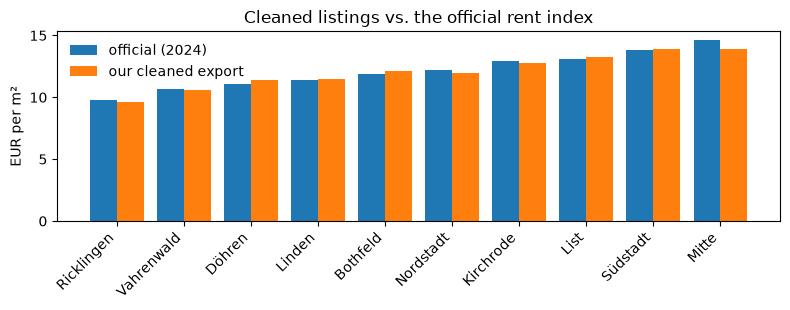

In [23]:
clean = deduplicated.dropna(subset=["cold_rent_eur", "living_area"])
estimate = (clean.groupby("district_key")
            .apply(lambda g: g["cold_rent_eur"].sum() / g["living_area"].sum(), include_groups=False)
            .rename("estimate_per_m2"))

comparison = joined.merge(estimate, on="district_key").sort_values("avg_rent_per_m2")

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(comparison))
ax.bar(x - 0.2, comparison["avg_rent_per_m2"], width=0.4, label="official (2024)")
ax.bar(x + 0.2, comparison["estimate_per_m2"], width=0.4, label="our cleaned export")
ax.set_xticks(x, comparison["district"], rotation=45, ha="right")
ax.set_ylabel("EUR per m²")
ax.set_title("Cleaned listings vs. the official rent index")
ax.legend(frameon=False)
plt.tight_layout()


# Well done!

What we did today, and what it cost: the export needed a type repair (Task 2), two kinds of missing
values handled differently (empty cells stay missing, disguised ones had to be *discovered*,
Task 3), a scope decision plus a rollup to the right granularity (Task 4), standardization before a
join could work at all (Task 5), and deduplication with blocking, including a date column that
needed one parser per format (Task 6). Nothing here was difficult mathematics, it was
bookkeeping, and skipping any single step would have produced a wrong average.

Next week: lecture 04, *Modeling*.
